# Proyek Analisis Data: E-Commerce Public Dataset (Olist)

- **Nama:** Lutfi Ibnu Marlianto
- **Email:** lutfiibnu2908@gmail.com
- **ID Dicoding:** lutfiibnm

**Dataset:** E-Commerce Public Dataset (Olist, Brasil), 9 tabel, periode pesanan September 2016 – Oktober 2018.

**Teknik analisis lanjutan:** Geospatial Analysis, RFM Analysis, dan Binning / Manual Grouping (tanpa algoritma machine learning).

## Menentukan Pertanyaan Bisnis

Pertanyaan disusun dengan metode SMART (Specific, Measurable, Action-Oriented, Relevant, Time-bound). Sasaran bisnisnya adalah menjaga pertumbuhan penjualan, memperluas jangkauan pasar, dan meningkatkan kepuasan serta retensi pelanggan.

1. **Tren dan kategori unggulan.** Berapa jumlah pesanan dan pendapatan (R$) per bulan sepanjang **Januari 2017 – Agustus 2018**, dan 5 kategori produk mana yang menyumbang pendapatan terbesar pada periode tersebut, sehingga tim dapat memprioritaskan stok dan promosi pada kategori unggulan?
2. **Konsentrasi wilayah.** State mana yang menyumbang pendapatan terbesar, berapa persen pendapatan (dari total) yang terkonsentrasi pada 3 state teratas, dan bagaimana pola sebarannya di peta sepanjang periode data (**September 2016 – Oktober 2018**), sehingga tim dapat menentukan prioritas wilayah untuk logistik dan ekspansi pemasaran?
3. **Keterlambatan dan kepuasan.** Berapa rata-rata skor ulasan dan persentase ulasan buruk (skor 1–2) pada pesanan yang tiba tepat waktu atau lebih cepat dibandingkan pesanan yang telat 1–3 hari, 4–7 hari, dan lebih dari 7 hari dari estimasi, sepanjang periode data (**September 2016 – Oktober 2018**), sehingga tim operasional dapat menentukan batas keterlambatan yang perlu ditangani lebih dulu?
4. **Segmentasi pelanggan.** Berapa persen pelanggan unik dan persen pendapatan pada tiap segmen RFM (*Recency, Frequency, Monetary*, dihitung terhadap tanggal acuan **30 Agustus 2018**), serta berapa persen pelanggan yang pernah membeli lebih dari satu kali, sehingga tim CRM dapat menentukan segmen prioritas untuk kampanye retensi dan reaktivasi?

**Definisi yang dipakai di seluruh analisis**
- *Pendapatan* = jumlah `price` pada `order_items` (tidak termasuk ongkos kirim).
- Analisis hanya memakai pesanan berstatus **delivered** yang punya tanggal tiba, karena pesanan lain belum final (dibatalkan, diproses, atau belum tiba).
- Pelanggan diidentifikasi dengan `customer_unique_id`, bukan `customer_id`, karena `customer_id` dibuat baru untuk setiap pesanan.
- Grafik tren (pertanyaan 1) dibatasi Januari 2017 – Agustus 2018 karena bulan lain hanya memuat sedikit pesanan (periode belum lengkap), sehingga akan memberi kesan lonjakan atau penurunan yang palsu.

## Import Semua Packages/Library yang Digunakan

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

# Palet konsisten: satu warna sorot untuk poin penting, abu-abu untuk konteks
HIGHLIGHT = "#2A7FA8"
MUTED = "#C9CED3"

## Data Wrangling

### Gathering Data
Sembilan file CSV dimuat dari folder `data/` ke dalam DataFrame. Kolom tanggal langsung diubah menjadi tipe `datetime` saat dibaca.

In [2]:
DATA = "data/"

customers_df = pd.read_csv(DATA + "customers_dataset.csv")
geolocation_df = pd.read_csv(DATA + "geolocation_dataset.csv")
order_items_df = pd.read_csv(DATA + "order_items_dataset.csv", parse_dates=["shipping_limit_date"])
order_payments_df = pd.read_csv(DATA + "order_payments_dataset.csv")
order_reviews_df = pd.read_csv(
    DATA + "order_reviews_dataset.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"],
)
orders_df = pd.read_csv(
    DATA + "orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
        "order_delivered_customer_date", "order_estimated_delivery_date",
    ],
)
category_df = pd.read_csv(DATA + "product_category_name_translation.csv")
products_df = pd.read_csv(DATA + "products_dataset.csv")
sellers_df = pd.read_csv(DATA + "sellers_dataset.csv")

tables = {
    "customers": customers_df, "geolocation": geolocation_df, "order_items": order_items_df,
    "order_payments": order_payments_df, "order_reviews": order_reviews_df, "orders": orders_df,
    "category_translation": category_df, "products": products_df, "sellers": sellers_df,
}
pd.DataFrame({n: d.shape for n, d in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
customers,99441,5
geolocation,1000163,5
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
orders,99441,8
category_translation,71,2
products,32951,9
sellers,3095,4


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


**Insight (Gathering Data)**
- Tabel `orders` menjadi pusat relasi: `customer_id` ke `customers`, dan `order_id` ke `order_items`, `order_payments`, serta `order_reviews`.
- `order_items` menghubungkan pesanan dengan `products` (lewat `product_id`) dan `sellers` (lewat `seller_id`).
- `geolocation` berisi lebih dari satu juta baris, jauh lebih besar dari tabel lain, sehingga perlu diringkas per kode pos sebelum digabung.

### Assessing Data
Pemeriksaan kualitas data meliputi jumlah baris, nilai kosong (*missing value*), duplikat, nilai tidak valid, dan ketidakkonsistenan yang relevan bagi pertanyaan bisnis.

In [4]:
def assess(name, df):
    return {
        "tabel": name, "baris": len(df), "kolom": df.shape[1],
        "total_missing": int(df.isna().sum().sum()), "duplikat": int(df.duplicated().sum()),
    }

pd.DataFrame([assess(n, d) for n, d in tables.items()])

,tabel,baris,kolom,total_missing,duplikat
0,customers,99441,5,0,0
1,geolocation,1000163,5,0,261831
2,order_items,112650,7,0,0
3,order_payments,103886,5,0,0
4,order_reviews,99224,7,145903,0
5,orders,99441,8,4908,0
6,category_translation,71,2,0,0
7,products,32951,9,2448,0
8,sellers,3095,4,0,0


In [5]:
# Rincian kolom yang memiliki nilai kosong
for name, df in tables.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f"[{name}]")
        print(miss.to_string(), end="\n\n")

[order_reviews]
review_comment_title      87656
review_comment_message    58247

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[products]
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2



In [6]:
# 1) Status pesanan dan tanggal tiba yang kosong
print("Distribusi status pesanan:")
print(orders_df["order_status"].value_counts().to_string())
print("\nTanggal tiba kosong per status:")
print(orders_df.groupby("order_status")["order_delivered_customer_date"].apply(lambda s: s.isna().sum()).to_string())

Distribusi status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Tanggal tiba kosong per status:
order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609


In [7]:
# 2) Pesanan dengan lebih dari satu ulasan, dan pesanan tanpa item
dup_review_orders = (order_reviews_df["order_id"].value_counts() > 1).sum()
print("Pesanan dengan >1 ulasan       :", dup_review_orders)
print("Pesanan tanpa baris order_items:", (~orders_df["order_id"].isin(order_items_df["order_id"])).sum())

# 3) Kategori produk
print("Produk tanpa kategori           :", products_df["product_category_name"].isna().sum())
no_translation = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("Kategori tanpa terjemahan       :", no_translation)

Pesanan dengan >1 ulasan       : 547
Pesanan tanpa baris order_items: 775
Produk tanpa kategori           : 610
Kategori tanpa terjemahan       : {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


In [8]:
# 4) Kualitas geolocation
print("Baris duplikat penuh      :", geolocation_df.duplicated().sum())
print("Kode pos unik             :", geolocation_df["geolocation_zip_code_prefix"].nunique())
outside = ~(geolocation_df["geolocation_lat"].between(-33.8, 5.3) & geolocation_df["geolocation_lng"].between(-73.9, -34.7))
print("Koordinat di luar Brasil  :", outside.sum())
print("Kode pos pelanggan tanpa data geolocation:",
      (~customers_df["customer_zip_code_prefix"].isin(geolocation_df["geolocation_zip_code_prefix"])).sum())

# 5) Identitas pelanggan
print("\ncustomer_id unik        :", customers_df["customer_id"].nunique())
print("customer_unique_id unik :", customers_df["customer_unique_id"].nunique())

Baris duplikat penuh      : 261831
Kode pos unik             : 19015
Koordinat di luar Brasil  : 42
Kode pos pelanggan tanpa data geolocation: 278

customer_id unik        : 99441
customer_unique_id unik : 96096


**Insight (Assessing Data)** dan **solusi yang dilakukan pada tahap Cleaning**

| No | Masalah yang ditemukan | Jenis masalah | Solusi pada tahap Cleaning |
|---|---|---|---|
| 1 | Pesanan `delivered` yang tanggal tiba kosong (8 pesanan). Tanggal tiba kosong pada status lain adalah wajar karena pesanan belum selesai. | *Missing value* | Analisis hanya memakai pesanan `delivered`, dan 8 pesanan tanpa tanggal tiba dibuang. |
| 2 | 610 produk tidak punya kategori, dan 2 nama kategori tidak ada di tabel terjemahan. | *Missing value*, *inconsistent value* | Tambahkan terjemahan manual untuk 2 kategori, dan isi kategori kosong dengan `unknown`. |
| 3 | 547 pesanan punya lebih dari satu ulasan. Jika digabung langsung, baris pesanan terduplikasi dan pendapatan terhitung ganda. | *Duplicate data* | Ambil satu ulasan terbaru per pesanan. |
| 4 | `geolocation` punya 261.831 baris duplikat penuh, 42 koordinat di luar wilayah Brasil, dan satu kode pos punya banyak titik koordinat. | *Duplicate data*, *invalid value* | Hapus duplikat, buang koordinat di luar Brasil, lalu ringkas menjadi satu titik (median) per kode pos. |
| 5 | `customer_id` (99.441) lebih banyak daripada `customer_unique_id` (96.096), artinya sebagian orang berbelanja lebih dari sekali. | *Inconsistent value* | Gunakan `customer_unique_id` sebagai identitas pelanggan. |
| 6 | Harga (`price`) sangat condong ke kanan, dengan nilai maksimum R$ 6.735 sementara mediannya sekitar R$ 75. | *Outlier* | Dipertahankan karena merupakan transaksi nyata. Dampaknya diatasi dengan membaca median bersama rata-rata dan memotong sumbu grafik pada persentil 99 untuk distribusi *monetary*. |
| 7 | Kolom komentar ulasan banyak yang kosong. | *Missing value* | Tidak diisi, karena kosong berarti pelanggan memang tidak menulis komentar. Kolom ini tidak dipakai dalam analisis. |

### Cleaning Data
Langkah pembersihan mengikuti tabel solusi pada tahap assessing:

1. Menyaring pesanan `delivered` yang memiliki tanggal tiba.
2. Menerjemahkan kategori produk, menambahkan dua terjemahan yang hilang, dan mengisi kategori kosong dengan `unknown`.
3. Menyisakan satu ulasan per pesanan (yang terbaru).
4. Membersihkan `geolocation`: hapus duplikat dan koordinat di luar Brasil, lalu ringkas menjadi satu titik (median) per kode pos.
5. Menggabungkan semua tabel menjadi satu tabel analisis dan menghitung durasi serta keterlambatan pengiriman.

In [9]:
# 1) Pesanan delivered yang memiliki tanggal tiba
delivered_df = orders_df[orders_df["order_status"] == "delivered"].copy()
n_before = len(delivered_df)
delivered_df = delivered_df.dropna(subset=["order_delivered_customer_date"])
print(f"Pesanan delivered: {n_before:,} -> {len(delivered_df):,} (dibuang {n_before - len(delivered_df)} tanpa tanggal tiba)")

Pesanan delivered: 96,478 -> 96,470 (dibuang 8 tanpa tanggal tiba)


In [10]:
# 2) Terjemahan kategori produk
extra_translation = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers"],
})
category_full = pd.concat([category_df, extra_translation], ignore_index=True)

products_clean = products_df.merge(category_full, on="product_category_name", how="left")
products_clean["product_category_name_english"] = products_clean["product_category_name_english"].fillna("unknown")
products_clean = products_clean[["product_id", "product_category_name_english"]]
print(products_clean["product_category_name_english"].eq("unknown").sum(), "produk berkategori 'unknown'")

610 produk berkategori 'unknown'


In [11]:
# 3) Satu ulasan per pesanan: ambil yang paling baru dijawab
reviews_clean = (
    order_reviews_df.sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")[["order_id", "review_score"]]
)
print("Baris ulasan:", len(order_reviews_df), "->", len(reviews_clean))

Baris ulasan: 99224 -> 98673


In [12]:
# 4) Geolocation: buang duplikat & koordinat di luar Brasil, lalu satu titik per kode pos
geo = geolocation_df.drop_duplicates()
inside_brazil = geo["geolocation_lat"].between(-33.8, 5.3) & geo["geolocation_lng"].between(-73.9, -34.7)
geo = geo[inside_brazil]
geo_zip = (
    geo.groupby("geolocation_zip_code_prefix")
    .agg(customer_lat=("geolocation_lat", "median"), customer_lng=("geolocation_lng", "median"))
    .reset_index()
)
print("Geolocation:", len(geolocation_df), "baris ->", len(geo_zip), "kode pos")

Geolocation: 1000163 baris -> 19010 kode pos


In [13]:
# 5) Menggabungkan semua tabel (level: satu baris = satu item pesanan)
main_df = (
    delivered_df
    .merge(customers_df, on="customer_id", how="inner")
    .merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
    .merge(order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]],
           on="order_id", how="inner")
    .merge(products_clean, on="product_id", how="left")
    .merge(reviews_clean, on="order_id", how="left")
)
main_df["product_category_name_english"] = main_df["product_category_name_english"].fillna("unknown")

# Durasi dan keterlambatan (dalam hari kalender). delay_days > 0 berarti terlambat dari estimasi.
purchase = main_df["order_purchase_timestamp"].dt.normalize()
arrived = main_df["order_delivered_customer_date"].dt.normalize()
estimated = main_df["order_estimated_delivery_date"].dt.normalize()
main_df["delivery_days"] = (arrived - purchase).dt.days
main_df["delay_days"] = (arrived - estimated).dt.days

# Validasi: tidak ada item yang terduplikasi akibat penggabungan
assert not main_df.duplicated(subset=["order_id", "order_item_id"]).any()
assert np.isclose(main_df["price"].sum(), order_items_df[order_items_df["order_id"].isin(delivered_df["order_id"])]["price"].sum())
print("Bentuk main_df:", main_df.shape)
main_df[["customer_lat", "customer_lng", "review_score"]].isna().sum()

Bentuk main_df: (110189, 23)


customer_lat    289
customer_lng    289
review_score    827
dtype: int64

In [14]:
# Simpan tabel analisis untuk dashboard
cols = [
    "order_id", "customer_unique_id", "order_purchase_timestamp", "customer_state", "customer_city",
    "customer_zip_code_prefix", "customer_lat", "customer_lng", "product_category_name_english",
    "price", "freight_value", "review_score", "delivery_days", "delay_days",
]
export_df = main_df[cols].copy()
export_df[["customer_lat", "customer_lng"]] = export_df[["customer_lat", "customer_lng"]].round(4)
export_df.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv:", export_df.shape)

main_data.csv: (110189, 14)


**Insight (Cleaning Data)**
- Penggabungan divalidasi dengan dua pemeriksaan: tidak ada baris item yang terduplikasi, dan total `price` pada tabel gabungan sama dengan total pada tabel sumber untuk pesanan yang sama. Artinya angka pendapatan tidak menggelembung.
- Sebanyak 289 baris item tidak punya koordinat (kode posnya tidak ada di `geolocation`) dan 827 baris tidak punya ulasan. Baris ini tetap dipertahankan dan hanya dikecualikan pada analisis yang membutuhkan kolom tersebut.
- Tabel akhir disimpan sebagai `dashboard/main_data.csv` dan menjadi sumber data dashboard.

## Exploratory Data Analysis (EDA)

EDA dilakukan pada `main_df` untuk memahami karakteristik data secara umum, lalu dilanjutkan dengan eksplorasi (grouping dan agregasi) yang secara langsung menjawab **keempat pertanyaan bisnis**.

### Eksplorasi Umum

In [15]:
main_df[["price", "freight_value", "review_score", "delivery_days", "delay_days"]].describe().round(2)

,price,freight_value,review_score,delivery_days,delay_days
count,110189.00,110189.00,109362.00,110189.00,110189.00
mean,119.98,19.95,4.08,12.41,-12.03
std,182.30,15.70,1.35,9.45,10.16
min,0.85,0.00,1.00,0.00,-147.00
25%,39.90,13.08,4.00,7.00,-17.00
50%,74.90,16.26,5.00,10.00,-13.00
75%,134.17,21.15,5.00,16.00,-7.00
max,6735.00,409.68,5.00,210.00,188.00


In [16]:
orders_level = main_df.drop_duplicates("order_id")

print("Jumlah pesanan delivered :", orders_level["order_id"].nunique())
print("Jumlah pelanggan unik    :", main_df["customer_unique_id"].nunique())
print("Total pendapatan (R$)    :", round(main_df["price"].sum(), 2))

orders_per_customer = main_df.groupby("customer_unique_id")["order_id"].nunique()
print("\nPelanggan dengan 1 pesanan :", f"{(orders_per_customer == 1).mean():.1%}")
print("Pelanggan dengan >=2 pesanan:", f"{(orders_per_customer >= 2).mean():.1%}")

Jumlah pesanan delivered : 96470
Jumlah pelanggan unik    : 93350
Total pendapatan (R$)    : 13220248.93

Pelanggan dengan 1 pesanan : 97.0%
Pelanggan dengan >=2 pesanan: 3.0%


In [17]:
# Pola hari dan jam pembelian (jumlah pesanan)
orders_level = orders_level.assign(
    weekday=orders_level["order_purchase_timestamp"].dt.day_name(),
    hour=orders_level["order_purchase_timestamp"].dt.hour,
)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(orders_level["weekday"].value_counts().reindex(weekday_order).to_string())
print("\nJam tersibuk:", orders_level["hour"].value_counts().head(3).to_dict())

weekday
Monday       15701
Tuesday      15502
Wednesday    15074
Thursday     14322
Friday       13684
Saturday     10555
Sunday       11632

Jam tersibuk: {16: 6475, 11: 6385, 14: 6383}


In [18]:
# Metode pembayaran pada pesanan yang dianalisis
pay = order_payments_df[order_payments_df["order_id"].isin(delivered_df["order_id"])]
pay.groupby("payment_type").agg(
    transaksi=("order_id", "count"), nilai=("payment_value", "sum"), rata_cicilan=("payment_installments", "mean")
).sort_values("nilai", ascending=False).round(1)

,transaksi,nilai,rata_cicilan
payment_type,,,
credit_card,74579,12100070.2,3.5
boleto,19191,2769932.6,1.0
voucher,5493,343013.2,1.0
debit_card,1485,208066.9,1.0


In [19]:
# Hubungan antarvariabel numerik pada level pesanan
orders_level[["price", "freight_value", "delivery_days", "delay_days", "review_score"]].corr().round(2)

,price,freight_value,delivery_days,delay_days,review_score
price,1.00,0.42,0.06,-0.01,-0.01
freight_value,0.42,1.00,0.21,-0.04,-0.04
delivery_days,0.06,0.21,1.00,0.61,-0.33
delay_days,-0.01,-0.04,0.61,1.00,-0.27
review_score,-0.01,-0.04,-0.33,-0.27,1.00


**Insight (Eksplorasi Umum)**
- Nilai `price` sangat condong ke kanan: rata-rata (R$ 120) jauh di atas median (R$ 75), dengan item termahal mencapai R$ 6.735. Ringkasan berbasis rata-rata perlu dibaca bersama median.
- Sekitar 97% pelanggan hanya bertransaksi satu kali. Ini penting untuk RFM karena variabel *frequency* hampir seragam.
- Pembayaran didominasi kartu kredit (rata-rata sekitar 3,5 cicilan), diikuti boleto. Pesanan paling ramai masuk pada hari kerja (Senin tertinggi) dan paling sepi pada Sabtu.
- Skor ulasan berkorelasi negatif dengan `delivery_days` (sekitar -0,33) dan `delay_days` (sekitar -0,27), sedangkan harga hampir tidak berkorelasi dengan skor ulasan. Ini baru indikasi awal yang diperiksa lebih lanjut pada pertanyaan 3.

### Eksplorasi Pertanyaan 1: Tren Bulanan dan Kategori Produk
Agregasi jumlah pesanan unik dan pendapatan per bulan (Januari 2017 – Agustus 2018), serta pendapatan per kategori produk.

In [20]:
monthly = (
    main_df.assign(month=main_df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(order_count=("order_id", "nunique"), revenue=("price", "sum"))
    .reset_index()
)
monthly = monthly[(monthly["month"] >= "2017-01-01") & (monthly["month"] <= "2018-08-01")]
monthly.assign(revenue=monthly["revenue"].round(0)).set_index("month")

,order_count,revenue
month,,
2017-01-01,750,111798.0
2017-02-01,1653,234223.0
2017-03-01,2546,359199.0
2017-04-01,2303,340670.0
2017-05-01,3545,489159.0
2017-06-01,3135,421923.0
2017-07-01,3872,481605.0
2017-08-01,4193,554700.0
2017-09-01,4150,607400.0


In [21]:
category_rev = (
    main_df[main_df["product_category_name_english"] != "unknown"]
    .groupby("product_category_name_english")
    .agg(revenue=("price", "sum"), order_count=("order_id", "nunique"))
    .sort_values("revenue", ascending=False)
)
top5 = category_rev.head(5)
bottom5 = category_rev.tail(5).sort_values("revenue", ascending=False)
print("Jumlah kategori:", len(category_rev))
print("Kontribusi 5 kategori teratas terhadap pendapatan:", f"{top5['revenue'].sum() / category_rev['revenue'].sum():.1%}")
print("Pendapatan 5 kategori terbawah (R$):", bottom5["revenue"].round(0).to_dict())

Jumlah kategori: 73
Kontribusi 5 kategori teratas terhadap pendapatan: 40.4%
Pendapatan 5 kategori terbawah (R$): {'flowers': 1110.0, 'home_comfort_2': 760.0, 'cds_dvds_musicals': 730.0, 'fashion_childrens_clothes': 520.0, 'security_and_services': 283.0}


**Hasil eksplorasi:** jumlah pesanan naik dari 750 (Jan 2017) menjadi 7.288 (Nov 2017), lalu berada di kisaran 6.000–7.000 per bulan pada 2018. Lima kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang 40,4% pendapatan dari 73 kategori.

### Eksplorasi Pertanyaan 2: Pendapatan per State
Agregasi jumlah pelanggan unik, jumlah pesanan, dan pendapatan per state pelanggan.

In [22]:
state_summary = (
    main_df.groupby("customer_state")
    .agg(customers=("customer_unique_id", "nunique"), orders=("order_id", "nunique"), revenue=("price", "sum"))
    .sort_values("revenue", ascending=False)
)
state_summary["revenue_share"] = state_summary["revenue"] / state_summary["revenue"].sum()
state_summary["revenue_per_order"] = state_summary["revenue"] / state_summary["orders"]
print("Kontribusi 3 state teratas:", f"{state_summary['revenue_share'].head(3).sum():.1%}")
state_summary.head(10).round({"revenue": 0, "revenue_share": 3, "revenue_per_order": 1})

Kontribusi 3 state teratas: 63.4%


,customers,orders,revenue,revenue_share,revenue_per_order
customer_state,,,,,
SP,39149,40494,5066563.0,0.383,125.1
RJ,11917,12350,1759651.0,0.133,142.5
MG,11001,11354,1552482.0,0.117,136.7
RS,5167,5344,728718.0,0.055,136.4
PR,4769,4923,666064.0,0.050,135.3
SC,3449,3546,507012.0,0.038,143.0
BA,3158,3256,493584.0,0.037,151.6
DF,2019,2080,296498.0,0.022,142.5
GO,1895,1957,282837.0,0.021,144.5


**Hasil eksplorasi:** SP menyumbang 38,3% pendapatan, RJ 13,3%, dan MG 11,7%. Tiga state teratas bersama-sama menyumbang 63,4% pendapatan. Pendapatan per pesanan relatif seragam antar state (sekitar R$ 125–150), jadi perbedaan pendapatan terutama berasal dari jumlah pesanan.

### Eksplorasi Pertanyaan 3: Keterlambatan Pengiriman dan Skor Ulasan
`delay_days` (tanggal tiba dikurangi tanggal estimasi, dalam hari) dikelompokkan ke dalam 5 kelompok melalui *binning* berdasarkan aturan bisnis, lalu dibandingkan rata-rata skor ulasan dan proporsi ulasan buruk (skor 1–2) pada tiap kelompok. Analisis dilakukan pada level pesanan (satu baris per pesanan) yang memiliki skor ulasan.

In [23]:
order_df = main_df.drop_duplicates("order_id").dropna(subset=["review_score"]).copy()

bins = [-np.inf, -8, 0, 3, 7, np.inf]
labels = ["Lebih cepat >7 hari", "Tepat waktu / lebih cepat 0-7 hari", "Telat 1-3 hari", "Telat 4-7 hari", "Telat >7 hari"]
order_df["delay_group"] = pd.cut(order_df["delay_days"], bins=bins, labels=labels)

delay_summary = (
    order_df.groupby("delay_group", observed=True)
    .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
         pct_score_1_2=("review_score", lambda s: (s <= 2).mean()))
)
delay_summary["order_share"] = delay_summary["orders"] / delay_summary["orders"].sum()
delay_summary.round({"avg_review": 2, "pct_score_1_2": 3, "order_share": 3})

,orders,avg_review,pct_score_1_2,order_share
delay_group,,,,
Lebih cepat >7 hari,70929,4.32,0.090,0.740
Tepat waktu / lebih cepat 0-7 hari,18514,4.19,0.104,0.193
Telat 1-3 hari,1852,3.29,0.321,0.019
Telat 4-7 hari,1748,2.10,0.677,0.018
Telat >7 hari,2781,1.70,0.793,0.029


**Hasil eksplorasi:** rata-rata skor ulasan turun dari sekitar 4,2–4,3 (tepat waktu atau lebih cepat) menjadi 3,3 (telat 1–3 hari), 2,1 (telat 4–7 hari), dan 1,7 (telat lebih dari 7 hari). Proporsi ulasan buruk naik dari 9–10% menjadi 79% pada kelompok telat lebih dari 7 hari. Sekitar 93% pesanan tiba tepat waktu atau lebih cepat dari estimasi.

### Eksplorasi Pertanyaan 4: Perhitungan RFM
**Tujuan teknik:** RFM mengelompokkan pelanggan berdasarkan kapan terakhir membeli (*Recency*), seberapa sering membeli (*Frequency*), dan berapa total belanjanya (*Monetary*), sehingga tim bisnis dapat menentukan strategi berbeda untuk tiap kelompok.

**Pengaturan**
- Tanggal acuan = satu hari setelah tanggal pembelian terakhir pada data (30 Agustus 2018).
- *Recency* dan *Monetary* diberi skor 1–4 menggunakan kuartil (4 = terbaik).
- *Frequency* **tidak** dikuartilkan karena sebagian besar pelanggan hanya membeli sekali, sehingga kuartil tidak akan membedakan apa pun. Pelanggan dikelompokkan berdasarkan aturan bisnis: 1 kali pembelian atau 2 kali lebih.
- Segmen dibentuk dengan aturan manual (*manual grouping*) dari kombinasi skor tersebut.

In [24]:
reference_date = main_df["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

rfm_df = (
    main_df.groupby("customer_unique_id")
    .agg(last_purchase=("order_purchase_timestamp", "max"),
         frequency=("order_id", "nunique"),
         monetary=("price", "sum"))
    .reset_index()
)
rfm_df["recency"] = (reference_date - rfm_df["last_purchase"].dt.normalize()).dt.days
rfm_df = rfm_df.drop(columns="last_purchase")
rfm_df[["recency", "frequency", "monetary"]].describe().round(1)

,recency,frequency,monetary
count,93350.0,93350.0,93350.0
mean,238.5,1.0,141.6
std,152.6,0.2,215.7
min,1.0,1.0,0.8
25%,115.0,1.0,47.6
50%,220.0,1.0,89.7
75%,347.0,1.0,154.7
max,714.0,15.0,13440.0


In [25]:
# Skor R dan M (1-4) memakai kuartil; rank(method="first") menghindari batas kuartil yang sama
rfm_df["r_score"] = pd.qcut(rfm_df["recency"].rank(method="first", ascending=False), 4, labels=[1, 2, 3, 4]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)


def segment(row):
    recent = row["r_score"] >= 3
    if row["frequency"] >= 2:
        return "Loyal" if recent else "Repeat - Lama Tidak Aktif"
    if recent:
        return "Baru - Big Spender" if row["m_score"] == 4 else "Baru"
    return "Dormant - Big Spender" if row["m_score"] == 4 else "Dormant"


rfm_df["segment"] = rfm_df.apply(segment, axis=1)

seg = (
    rfm_df.groupby("segment")
    .agg(customers=("customer_unique_id", "count"), avg_recency=("recency", "mean"),
         avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"), total_monetary=("monetary", "sum"))
    .sort_values("total_monetary", ascending=False)
)
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["total_monetary"] / seg["total_monetary"].sum()
seg.round({"avg_recency": 0, "avg_frequency": 2, "avg_monetary": 0, "total_monetary": 0, "customer_share": 3, "revenue_share": 3})

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_share,revenue_share
segment,,,,,,,
Dormant - Big Spender,10934,367.0,1.00,353.0,3857945.0,0.117,0.292
Baru - Big Spender,10725,112.0,1.00,353.0,3789220.0,0.115,0.287
Baru,34407,112.0,1.00,71.0,2446972.0,0.369,0.185
Dormant,34483,364.0,1.00,70.0,2397704.0,0.369,0.181
Loyal,1543,113.0,2.14,264.0,407785.0,0.017,0.031
Repeat - Lama Tidak Aktif,1258,353.0,2.08,255.0,320624.0,0.013,0.024


**Hasil eksplorasi:** 97% pelanggan hanya membeli satu kali (3% membeli lebih dari sekali). Median *recency* sekitar 220 hari. Dua segmen *Big Spender* (*Baru* dan *Dormant*) berisi sekitar 23% pelanggan tetapi menyumbang sekitar 58% pendapatan.

## Visualization & Explanatory Analysis

Prinsip visualisasi yang diterapkan:
- **Satu pesan per grafik**, dengan judul yang menyatakan temuan utama.
- **Warna sorot** hanya untuk elemen yang ingin ditekankan, warna lain abu-abu.
- **Grafik batang selalu dimulai dari nol** dan diurutkan, agar perbandingan tidak menyesatkan.
- **Satuan dan label sumbu** dicantumkan, dan data yang dipakai dibatasi pada periode yang lengkap.

### Pertanyaan 1: Bagaimana tren pesanan dan pendapatan per bulan (Jan 2017 – Agu 2018), dan 5 kategori mana yang paling besar kontribusinya?

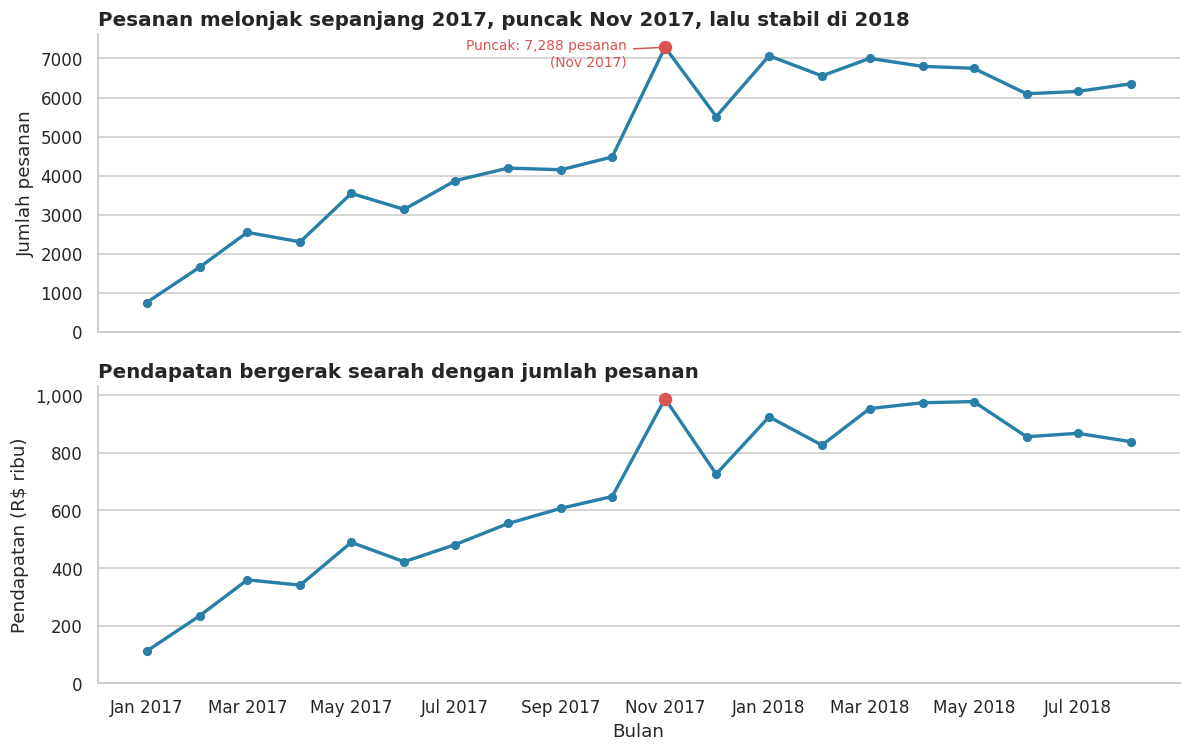

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
peak = monthly.loc[monthly["order_count"].idxmax()]

for ax, col, ylabel in zip(axes, ["order_count", "revenue"], ["Jumlah pesanan", "Pendapatan (R$ ribu)"]):
    ax.plot(monthly["month"], monthly[col], color=HIGHLIGHT, linewidth=2.2, marker="o", markersize=5)
    ax.scatter(peak["month"], peak[col], color="#D9534F", zorder=5, s=60)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    ax.grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}"))
axes[0].set_title("Pesanan melonjak sepanjang 2017, puncak Nov 2017, lalu stabil di 2018")
axes[0].annotate(f"Puncak: {peak['order_count']:,.0f} pesanan\n({peak['month']:%b %Y})",
                 xy=(peak["month"], peak["order_count"]), xytext=(-25, -4),
                 textcoords="offset points", fontsize=9, color="#D9534F", ha="right", va="center",
                 arrowprops=dict(arrowstyle="-", color="#D9534F"))
axes[1].set_title("Pendapatan bergerak searah dengan jumlah pesanan")
axes[1].set_xlabel("Bulan")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

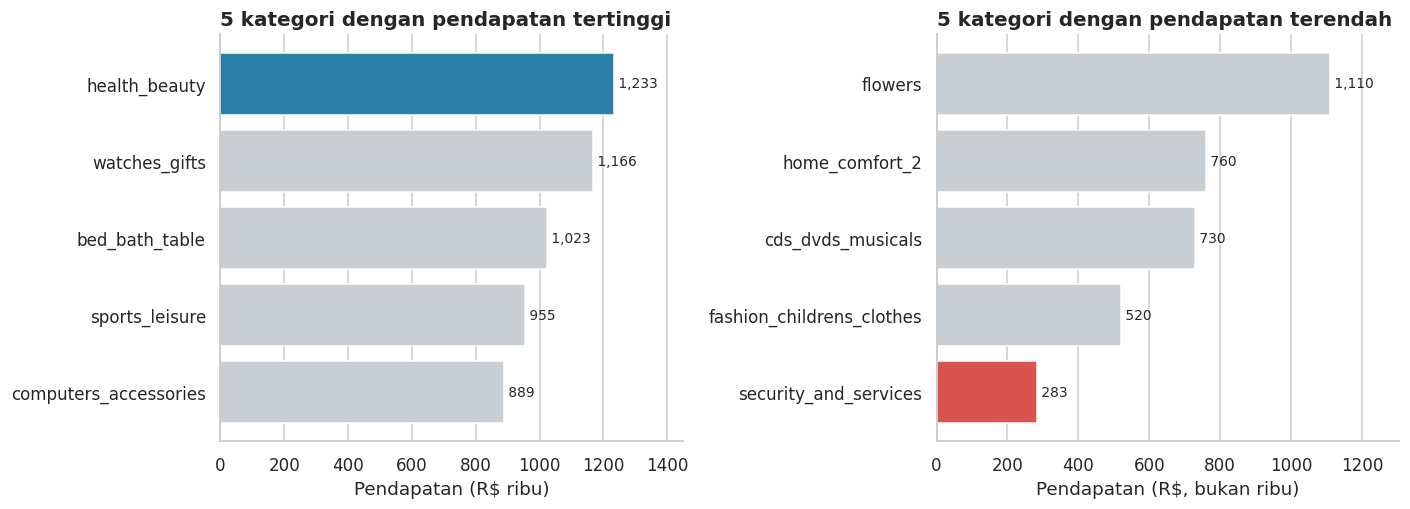

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Kiri: 5 kategori teratas (satuan R$ ribu), yang terbesar disorot
axes[0].barh(top5.index[::-1], top5["revenue"][::-1] / 1000, color=[MUTED] * 4 + [HIGHLIGHT])
axes[0].set_title("5 kategori dengan pendapatan tertinggi")
axes[0].set_xlabel("Pendapatan (R$ ribu)")

# Kanan: 5 kategori terendah (satuan R$ penuh karena nilainya kecil), yang terkecil disorot
axes[1].barh(bottom5.index[::-1], bottom5["revenue"][::-1], color=["#D9534F"] + [MUTED] * 4)
axes[1].set_title("5 kategori dengan pendapatan terendah")
axes[1].set_xlabel("Pendapatan (R$, bukan ribu)")

for ax in axes:
    ax.grid(axis="y", visible=False)
    for p in ax.patches:
        ax.text(p.get_width(), p.get_y() + p.get_height() / 2, f" {p.get_width():,.0f}", va="center", fontsize=9)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.12)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1**
- Jumlah pesanan tumbuh pesat dari awal 2017, mencapai puncak pada **November 2017** (7.288 pesanan). Lonjakan ini kemungkinan terkait promosi akhir tahun seperti Black Friday, tetapi data tidak memuat informasi promosi sehingga ini hanya dugaan. Sepanjang 2018 pesanan bertahan di kisaran 6.000–7.000 per bulan, artinya pertumbuhan melandai dan bisnis masuk fase stabil, bukan terus naik.
- Pendapatan mengikuti pola pesanan, sehingga pertumbuhan bersumber dari jumlah transaksi, bukan dari kenaikan nilai per pesanan (rata-rata pendapatan per pesanan relatif datar di kisaran R$ 130–150).
- Lima kategori teratas (kecantikan & kesehatan, jam tangan & hadiah, tempat tidur-mandi-meja, olahraga, aksesoris komputer) menyumbang sekitar 40% pendapatan, sedangkan pendapatan lima kategori terbawah hanya R$ 283 hingga R$ 1.110 per kategori.
- Kategori terbawah memiliki volume transaksi sangat kecil, sehingga perbandingannya sebaiknya dibaca sebagai "kategori ceruk", bukan sebagai bukti performa buruk.

### Pertanyaan 2: State mana yang menyumbang pendapatan terbesar, dan berapa persen pendapatan yang terkonsentrasi pada 3 state teratas?

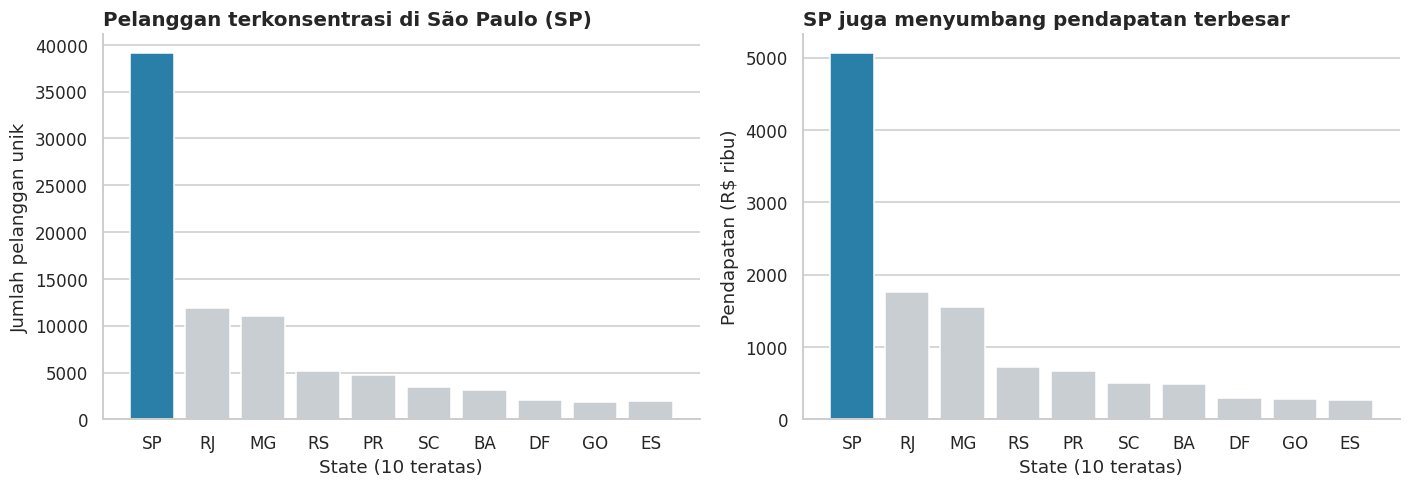

In [28]:
top10 = state_summary.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

axes[0].bar(top10.index, top10["customers"], color=[HIGHLIGHT] + [MUTED] * 9)
axes[0].set_title("Pelanggan terkonsentrasi di São Paulo (SP)")
axes[0].set_ylabel("Jumlah pelanggan unik")

axes[1].bar(top10.index, top10["revenue"] / 1000, color=[HIGHLIGHT] + [MUTED] * 9)
axes[1].set_title("SP juga menyumbang pendapatan terbesar")
axes[1].set_ylabel("Pendapatan (R$ ribu)")

for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("State (10 teratas)")
plt.tight_layout()
plt.show()

**Insight Pertanyaan 2**
- **São Paulo (SP)** adalah pasar terbesar dengan selisih sangat jauh dari state lain, baik dari jumlah pelanggan maupun pendapatan. SP saja menyumbang sekitar 38% pendapatan, dan tiga state teratas (SP, RJ, MG) bersama-sama sekitar 63%.
- Pola sebaran di peta dibahas pada bagian Analisis Lanjutan (Geospatial Analysis) di bawah.

### Pertanyaan 3: Apakah keterlambatan pengiriman berhubungan dengan skor ulasan yang lebih rendah?

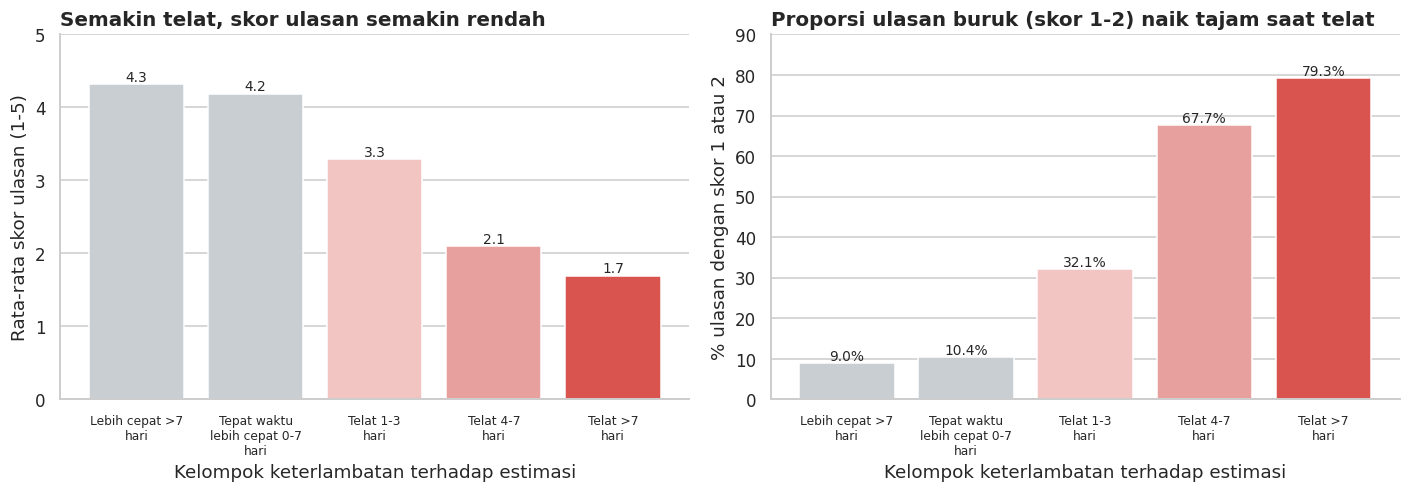

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = [MUTED, MUTED, "#F2C4C2", "#E8A09E", "#D9534F"]

axes[0].bar(delay_summary.index.astype(str), delay_summary["avg_review"], color=colors)
axes[0].set_title("Semakin telat, skor ulasan semakin rendah")
axes[0].set_ylabel("Rata-rata skor ulasan (1-5)")
axes[0].set_ylim(0, 5)

axes[1].bar(delay_summary.index.astype(str), delay_summary["pct_score_1_2"] * 100, color=colors)
axes[1].set_title("Proporsi ulasan buruk (skor 1-2) naik tajam saat telat")
axes[1].set_ylabel("% ulasan dengan skor 1 atau 2")
axes[1].set_ylim(0, 90)

for ax in axes:
    ax.set_xlabel("Kelompok keterlambatan terhadap estimasi")
    ax.tick_params(axis="x", labelsize=8)
    ax.set_xticklabels([l.replace(" / ", "\n").replace(" hari", "\nhari") for l in delay_summary.index.astype(str)])
    ax.grid(axis="x", visible=False)
    for p in ax.patches:
        v = p.get_height()
        ax.text(p.get_x() + p.get_width() / 2, v, f"{v:.1f}" + ("%" if ax is axes[1] else ""), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 3**
- Pesanan yang tiba tepat waktu atau lebih cepat dari estimasi punya rata-rata skor ulasan sekitar 4,2–4,3 dengan hanya sekitar 9–10% ulasan buruk (skor 1–2). Pada pesanan yang telat lebih dari seminggu, rata-rata skor turun menjadi sekitar 1,7 dan sekitar 79% ulasannya buruk, atau hampir sembilan kali lipat.
- Penurunan sudah tajam sejak keterlambatan 1–3 hari (rata-rata skor sekitar 3,3), sehingga toleransi pelanggan terhadap keterlambatan sangat kecil.
- Hanya sekitar 7% pesanan yang melewati estimasi. Sekitar 93% tiba tepat waktu atau lebih cepat, sehingga estimasi pengiriman cenderung konservatif. Sebagian kecil pesanan telat itulah yang paling merusak kepuasan.
- Ini adalah **hubungan (asosiasi), bukan bukti sebab-akibat**: pesanan yang telat juga bisa disertai masalah lain (barang rusak atau tidak sesuai) yang ikut menurunkan skor.

## Analisis Lanjutan

Dua teknik lanjutan diterapkan tanpa algoritma machine learning: **Geospatial Analysis** untuk memperdalam pertanyaan 2, dan **RFM Analysis** untuk menjawab pertanyaan 4. Teknik *Binning / Manual Grouping* sudah diterapkan pada pertanyaan 3 (kelompok keterlambatan) dan pada pembentukan segmen RFM.

### Geospatial Analysis (melengkapi Pertanyaan 2)
**Tujuan:** memetakan pelanggan berdasarkan lokasi untuk mengidentifikasi apakah pasar terkonsentrasi secara geografis dan wilayah mana yang masih tipis. Peta memakai titik tengah (median) koordinat kode pos. Titik abu-abu menunjukkan setiap kode pos pelanggan (membentuk kerangka peta Brasil), sedangkan lingkaran biru adalah ringkasan per state dengan **luas lingkaran proporsional terhadap pendapatan**.

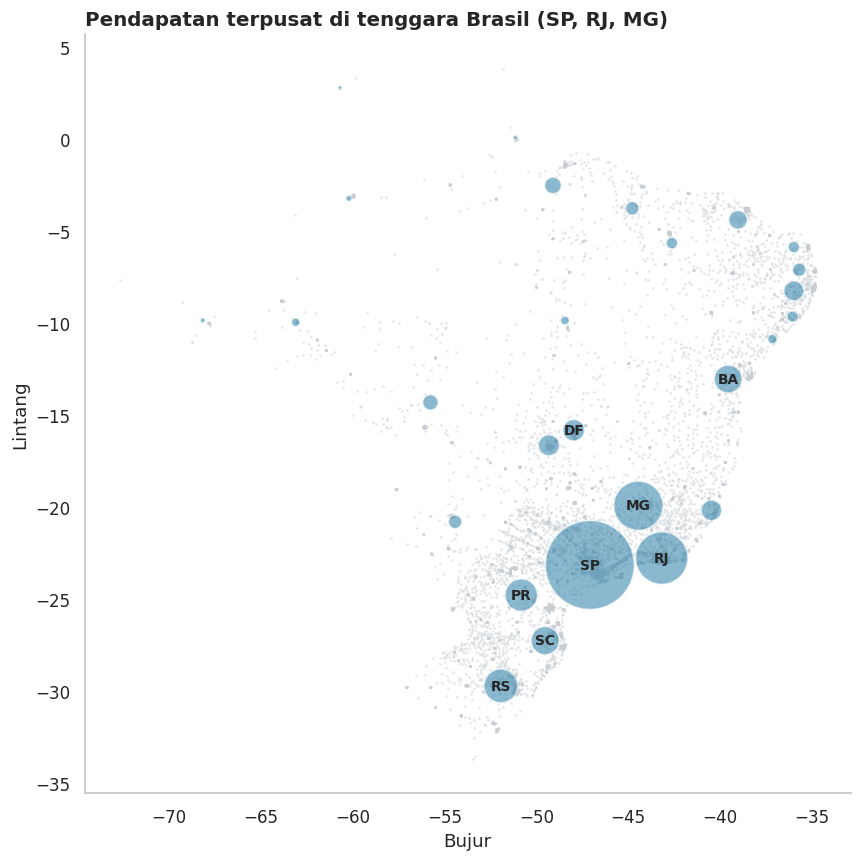

In [30]:
zip_level = (
    main_df.dropna(subset=["customer_lat", "customer_lng"])
    .groupby("customer_zip_code_prefix")
    .agg(lat=("customer_lat", "first"), lng=("customer_lng", "first"))
)

# Titik pusat tiap state = rata-rata koordinat pelanggan, dibobot pendapatan
geo_orders = main_df.dropna(subset=["customer_lat", "customer_lng"])
state_geo = (
    geo_orders.groupby("customer_state")
    .apply(lambda g: pd.Series({
        "lat": np.average(g["customer_lat"], weights=g["price"]),
        "lng": np.average(g["customer_lng"], weights=g["price"]),
    }))
    .join(state_summary[["revenue", "revenue_share"]])
)

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(zip_level["lng"], zip_level["lat"], s=3, color=MUTED, alpha=0.5, linewidths=0)
ax.scatter(state_geo["lng"], state_geo["lat"], s=state_geo["revenue"] / 1500,
           color=HIGHLIGHT, alpha=0.55, edgecolors="white", linewidths=1)
for st, row in state_geo.sort_values("revenue", ascending=False).head(8).iterrows():
    ax.annotate(st, (row["lng"], row["lat"]), ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_title("Pendapatan terpusat di tenggara Brasil (SP, RJ, MG)")
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
ax.set_aspect("equal")
ax.grid(False)
plt.tight_layout()
plt.show()

**Insight Geospatial**
- Pelanggan dan pendapatan menumpuk di tenggara dan selatan Brasil, dengan sebaran lebih tipis di pesisir timur laut. Wilayah utara dan tengah-barat sangat jarang, padahal wilayahnya luas. Pasar yang belum tergarap ini bisa menjadi peluang ekspansi, meski mungkin terkendala logistik.
- Perlu diingat bahwa titik pada peta adalah pusat kode pos, bukan alamat pelanggan sebenarnya, sehingga peta cocok untuk melihat pola umum dan bukan lokasi presisi.

### RFM Analysis (menjawab Pertanyaan 4)
**Tujuan:** melihat distribusi *Recency*, *Frequency*, dan *Monetary*, lalu menilai besar dan nilai tiap segmen pelanggan untuk menentukan prioritas kampanye retensi dan reaktivasi.

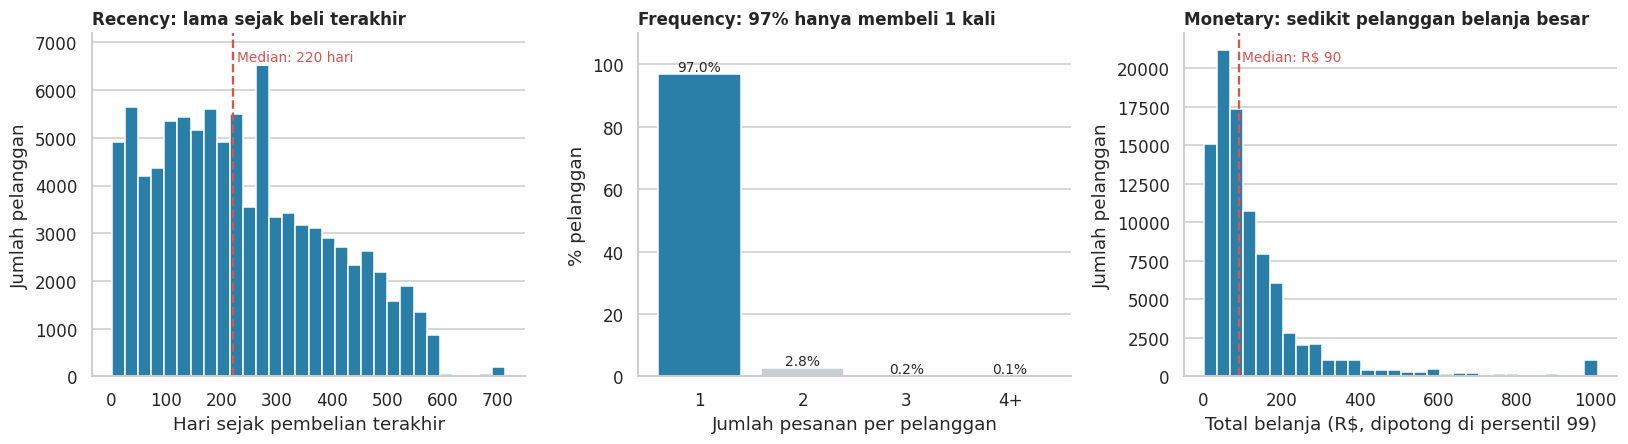

In [31]:
# Distribusi ketiga dimensi RFM (top 5 pelanggan tidak informatif: Recency terbaru semuanya 1 hari)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].hist(rfm_df["recency"], bins=30, color=HIGHLIGHT)
axes[0].axvline(rfm_df["recency"].median(), color="#D9534F", linestyle="--", linewidth=1.5)
axes[0].text(rfm_df["recency"].median() + 8, axes[0].get_ylim()[1] * 0.92,
             f"Median: {rfm_df['recency'].median():.0f} hari", color="#D9534F", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
axes[0].set_title("Recency: lama sejak beli terakhir", fontsize=11)
axes[0].set_xlabel("Hari sejak pembelian terakhir")
axes[0].set_ylabel("Jumlah pelanggan")

freq = rfm_df["frequency"].clip(upper=4).value_counts(normalize=True).sort_index() * 100
axes[1].bar(["1", "2", "3", "4+"], freq.values, color=[HIGHLIGHT, MUTED, MUTED, MUTED])
for i, v in enumerate(freq.values):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Frequency: 97% hanya membeli 1 kali", fontsize=11)
axes[1].set_xlabel("Jumlah pesanan per pelanggan")
axes[1].set_ylabel("% pelanggan")
axes[1].set_ylim(0, 110)

cap = rfm_df["monetary"].quantile(0.99)
axes[2].hist(rfm_df["monetary"].clip(upper=cap), bins=30, color=HIGHLIGHT)
axes[2].axvline(rfm_df["monetary"].median(), color="#D9534F", linestyle="--", linewidth=1.5)
axes[2].text(rfm_df["monetary"].median() + 8, axes[2].get_ylim()[1] * 0.92,
             rf"Median: R\$ {rfm_df['monetary'].median():.0f}", color="#D9534F", fontsize=9)
axes[2].set_title("Monetary: sedikit pelanggan belanja besar", fontsize=11)
axes[2].set_xlabel(rf"Total belanja (R\$, dipotong di persentil 99)")
axes[2].set_ylabel("Jumlah pelanggan")

for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

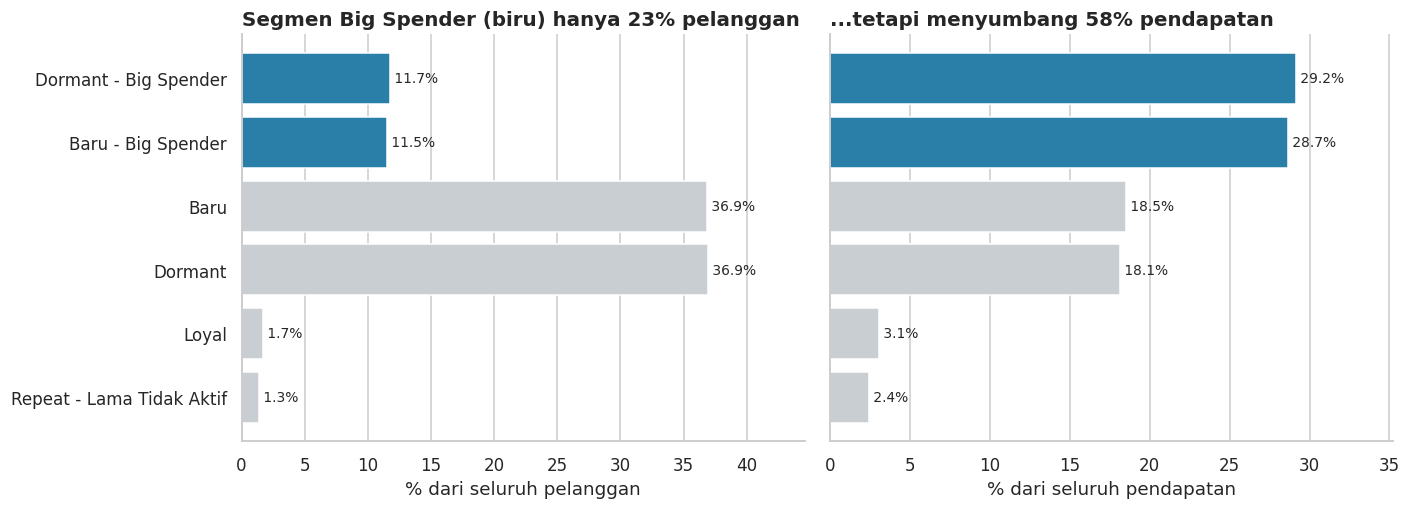

In [32]:
order = seg.sort_values("revenue_share", ascending=True).index
plot = seg.loc[order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

axes[0].set_xlabel("% dari seluruh pelanggan")

is_big = ["Big Spender" in s for s in plot.index]
hl = [HIGHLIGHT if b else MUTED for b in is_big]
axes[0].barh(plot.index, plot["customer_share"] * 100, color=hl)
axes[1].barh(plot.index, plot["revenue_share"] * 100, color=hl)
big_c = plot.loc[is_big, "customer_share"].sum() * 100
big_r = plot.loc[is_big, "revenue_share"].sum() * 100
axes[0].set_title(f"Segmen Big Spender (biru) hanya {big_c:.0f}% pelanggan")
axes[1].set_title(f"...tetapi menyumbang {big_r:.0f}% pendapatan")
axes[1].set_xlabel("% dari seluruh pendapatan")

for ax in axes:
    ax.grid(axis="y", visible=False)
    for p in ax.patches:
        ax.text(p.get_width(), p.get_y() + p.get_height() / 2, f" {p.get_width():.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.15)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 4**
- Pelanggan yang berbelanja **lebih dari satu kali hanya sekitar 3%**. Hampir seluruh basis pelanggan adalah pembeli sekali. Itulah sebabnya *frequency* dikelompokkan secara manual dan bukan lewat kuartil. Median *recency* sekitar 220 hari, jadi sebagian besar pelanggan sudah lama tidak bertransaksi.
- Segmen **Loyal** dan **Repeat - Lama Tidak Aktif** berukuran sangat kecil (sekitar 3% pelanggan dan 5,5% pendapatan), tetapi belanja rata-rata mereka (sekitar R$ 255–264) lebih dari tiga kali lipat pembeli sekali biasa (sekitar R$ 70).
- Segmen **Big Spender** (skor monetary tertinggi, belanja rata-rata sekitar R$ 353) hanya sekitar 23% pelanggan tetapi menyumbang sekitar 58% pendapatan. Separuh dari mereka (*Dormant - Big Spender*, hampir 11 ribu pelanggan) terakhir membeli sekitar satu tahun lalu, sehingga menjadi target reaktivasi paling bernilai.
- Mayoritas pelanggan lainnya adalah pembeli sekali dengan nilai belanja kecil, baik yang masih baru maupun yang sudah dormant. Tantangan utama bisnis adalah **mengubah pembeli pertama menjadi pelanggan berulang**.

## Conclusion & Recommendation

### Kesimpulan
- **Pertanyaan 1 (tren dan kategori).** Pesanan tumbuh pesat sepanjang 2017 dan memuncak pada November 2017 (7.288 pesanan), lalu stabil di 6.000–7.000 per bulan pada 2018. Pendapatan mengikuti jumlah pesanan. Lima kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang sekitar 40% pendapatan, sedangkan kategori terbawah adalah produk ceruk dengan pendapatan hanya R$ 283–1.110 per kategori.
- **Pertanyaan 2 (wilayah).** Pendapatan sangat terkonsentrasi: SP menyumbang sekitar 38% dan tiga state teratas (SP, RJ, MG) sekitar 63%. Peta menunjukkan wilayah utara dan tengah-barat masih sangat tipis.
- **Pertanyaan 3 (keterlambatan dan kepuasan).** Keterlambatan berasosiasi kuat dengan skor ulasan yang lebih rendah: rata-rata skor 4,2–4,3 untuk pesanan tepat waktu atau lebih cepat, turun menjadi 3,3 (telat 1–3 hari) dan 1,7 (telat lebih dari 7 hari). Hanya sekitar 7% pesanan yang telat.
- **Pertanyaan 4 (segmentasi pelanggan).** Sekitar 97% pelanggan hanya membeli sekali. Segmen *Big Spender* hanya sekitar 23% pelanggan tetapi menyumbang sekitar 58% pendapatan, dan separuhnya sudah dormant.

### Rekomendasi (Action Items)
1. **Prioritaskan kategori unggulan.** Pastikan ketersediaan stok dan alokasikan promosi pada 5 kategori teratas, serta siapkan kampanye akhir tahun lebih awal. Lonjakan November 2017 kemungkinan terkait promosi akhir tahun, tetapi hal ini perlu dikonfirmasi dengan data promosi yang tidak tersedia pada dataset ini.
2. **Perkuat logistik di SP, RJ, dan MG** sebagai pasar inti, dan uji coba terbatas (misalnya promo ongkos kirim) di satu atau dua state dengan pelanggan tipis sebelum melakukan ekspansi besar.
3. **Tangani risiko keterlambatan secara proaktif.** Pantau pesanan yang berisiko melewati estimasi, kirim pemberitahuan lebih awal kepada pelanggan, dan jadikan pesanan yang telat lebih dari 3 hari sebagai prioritas penanganan karena skor ulasan sudah turun tajam di titik itu.
4. **Dorong pembelian kedua dan reaktivasi.** Berikan voucher pembelian kedua kepada pelanggan baru (segmen *Baru* dan *Baru - Big Spender*), dan jalankan kampanye reaktivasi khusus untuk segmen *Dormant - Big Spender* (sekitar 11 ribu pelanggan).

### Keterbatasan
Analisis penjualan hanya mencakup pesanan *delivered*. Koordinat adalah pusat kode pos. Hubungan keterlambatan dan ulasan bersifat asosiasi. Periode data berakhir pada Agustus 2018, sehingga temuan perlu diperbarui bila ada data terbaru.